<a href="https://colab.research.google.com/github/AlfredaDhaifullah04/PCVK_Ganjil_2026/blob/main/PCVK_M10_W10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Modul 10 - Dasar-Dasar Deteksi Obyek

konsep dan implementasi praktikum pengolahan citra dan visi komputer yang mencakup deteksi objek dasar (template matching, edge, corner, grid, dan contour detection), feature matching, serta pendeteksian wajah (face detection) dan pengenalan karakter berbasis Deep Learning (CNN).

## D1. Praktikum Deteksi Obyek Dasar

### 1. Import Library dan Akses GDrive


In [2]:
#import library yang dibutuhkan
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

#akses drive
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 2. Implementasi 6 metode template matching
Menggunakan gambar `cats_and_bunnies.jpg` dan `cat2_templatejpg.jpg`.


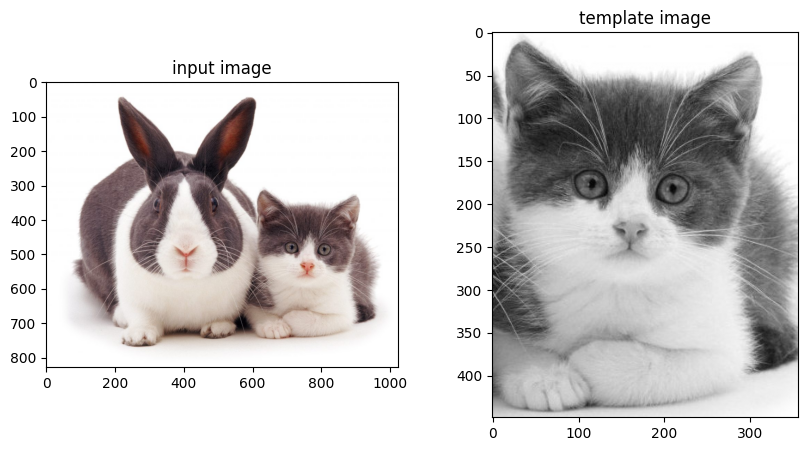

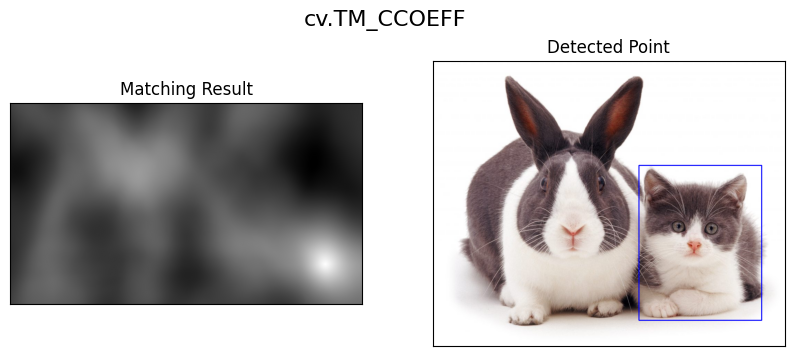

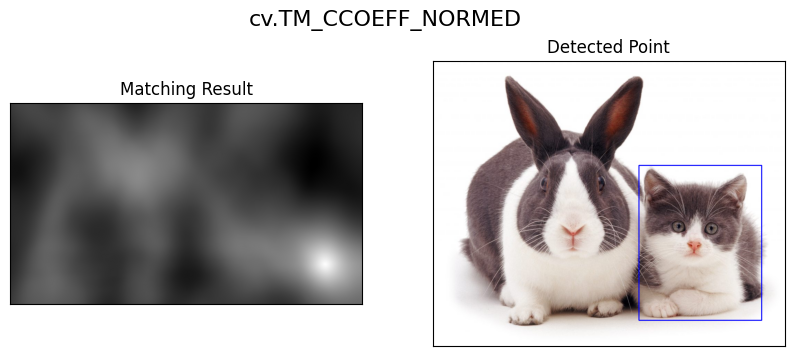

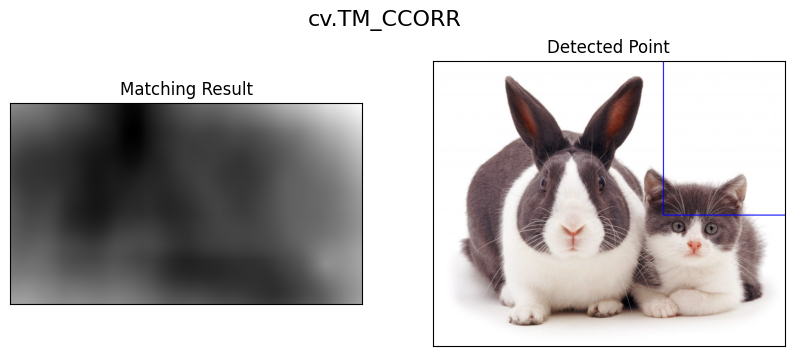

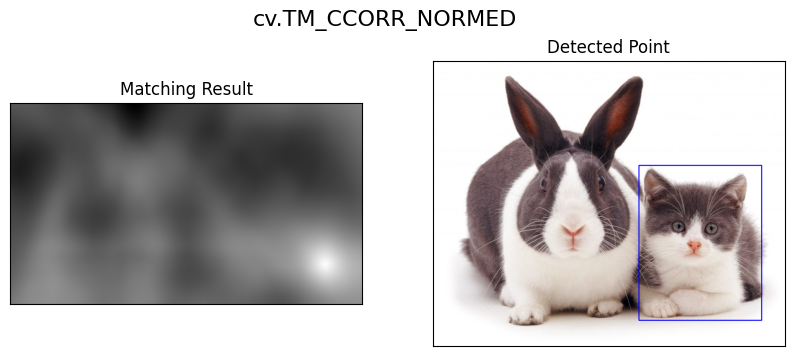

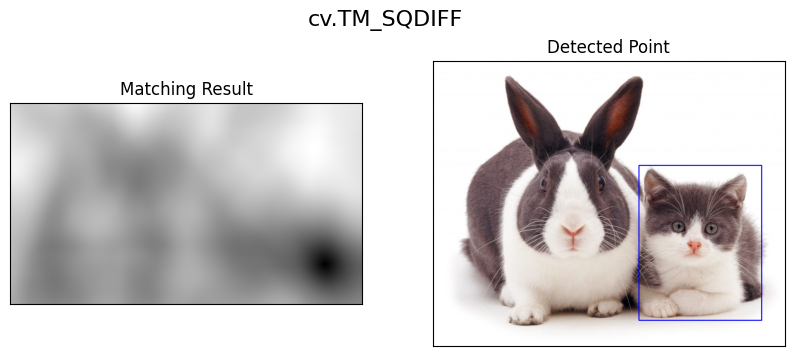

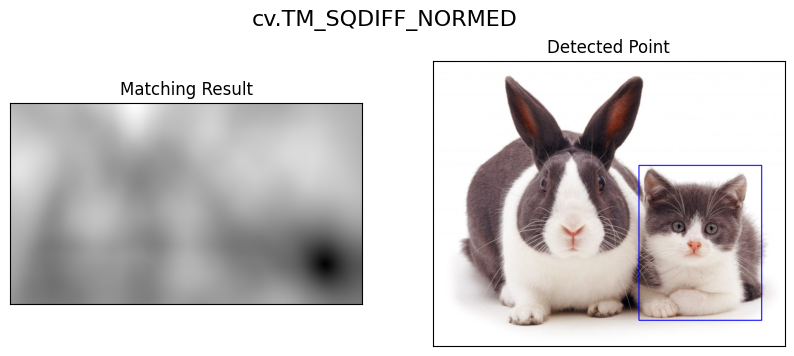

In [3]:
# Path disesuaikan dengan folder di drive
img_rgb = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/cats_and_bunnies.jpg')
img_gray = cv.cvtColor(img_rgb, cv.COLOR_BGR2GRAY)
template = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/cat2_templatejpg.jpg', 0)
w, h = template.shape[::-1]

# Menampilkan gambar awal
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(cv.cvtColor(img_rgb, cv.COLOR_BGR2RGB)), plt.title('input image')
plt.subplot(122), plt.imshow(template, cmap='gray'), plt.title('template image')
plt.show()

methods = ['cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED', 'cv.TM_CCORR',
            'cv.TM_CCORR_NORMED', 'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED']

for meth in methods:
    img = img_rgb.copy()
    method = eval(meth)

    # Apply template Matching
    res = cv.matchTemplate(img_gray, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc

    bottom_right = (top_left[0] + w, top_left[1] + h)
    cv.rectangle(img, top_left, bottom_right, (255, 0, 0), 2)

    plt.figure(figsize=(10, 4))
    plt.suptitle(meth, fontsize=16)
    plt.subplot(121), plt.imshow(res, cmap='gray'), plt.title('Matching Result'), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)), plt.title('Detected Point'), plt.xticks([]), plt.yticks([])
    plt.show()


### 3. Template Matching Tanpa Library (Multiple Object)
Menggunakan `bahrain.jpg` dan `bahrain-template.jpg`.


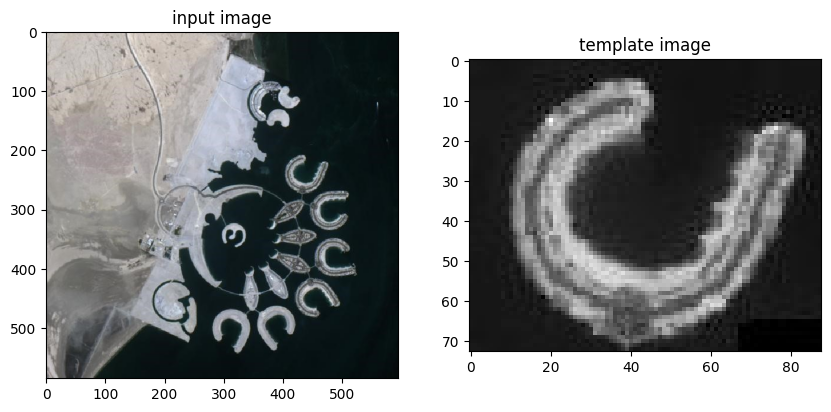

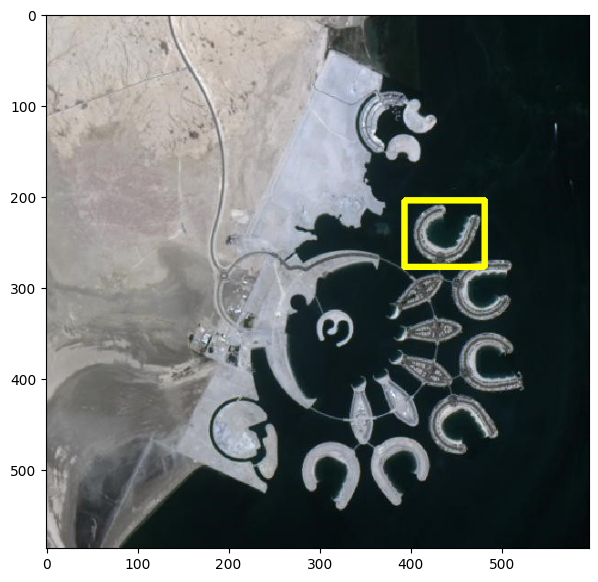

In [4]:
img_rgb = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/bahrain.jpg')
img_gray = cv.cvtColor(img_rgb, cv.COLOR_BGR2GRAY)
template = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/bahrain-template.jpg', 0)
w, h = template.shape[::-1]

plt.figure(figsize=(10,5))
plt.subplot(121), plt.imshow(cv.cvtColor(img_rgb, cv.COLOR_BGR2RGB)), plt.title('input image')
plt.subplot(122), plt.imshow(template, cmap='gray'), plt.title('template image')
plt.show()

res = cv.matchTemplate(img_gray, template, cv.TM_CCOEFF_NORMED)
threshold = 0.8
loc = np.where(res >= threshold)

for pt in zip(*loc[::-1]):
    cv.rectangle(img_rgb, pt, (pt[0] + w, pt[1] + h), (0,255,255), 2)

plt.figure(figsize=(7,7))
plt.imshow(cv.cvtColor(img_rgb, cv.COLOR_BGR2RGB))
plt.show()


### 4. Edge Detection (Sobel, Canny, Laplacian)
Menggunakan gambar `car-park.jpg`.


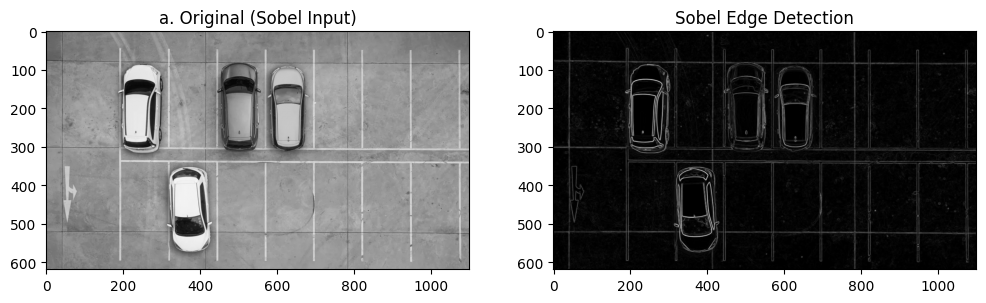

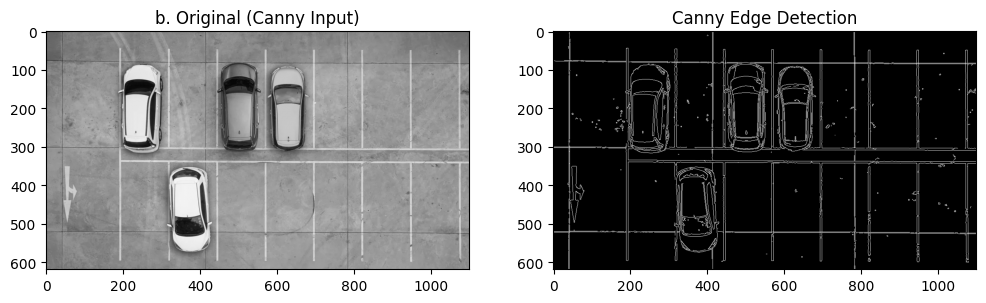

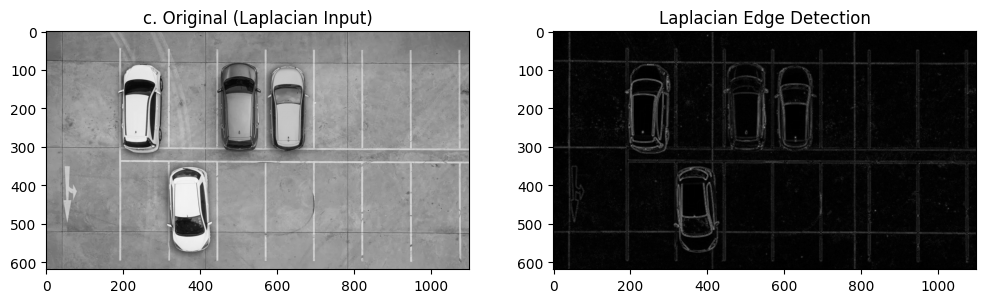

In [5]:
img = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/car-park.jpg', 0)

# Sobel Edge Detection
sobelx = cv.Sobel(img, cv.CV_64F, 1, 0, ksize=3)
sobely = cv.Sobel(img, cv.CV_64F, 0, 1, ksize=3)
sobel_combined = cv.magnitude(sobelx, sobely)

plt.figure(figsize=(12, 4))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('a. Original (Sobel Input)')
plt.subplot(122), plt.imshow(sobel_combined, cmap='gray'), plt.title('Sobel Edge Detection')
plt.show()

# Canny Edge Detection
edges = cv.Canny(img, 100, 200)
plt.figure(figsize=(12, 4))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('b. Original (Canny Input)')
plt.subplot(122), plt.imshow(edges, cmap='gray'), plt.title('Canny Edge Detection')
plt.show()

# Laplacian Edge Detection
# Blur gambar dulu agar lebih baik hasilnya
img_blur = cv.GaussianBlur(img, (3,3), 0)
laplacian = cv.Laplacian(img_blur, cv.CV_64F)
plt.figure(figsize=(12, 4))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('c. Original (Laplacian Input)')
plt.subplot(122), plt.imshow(np.absolute(laplacian), cmap='gray'), plt.title('Laplacian Edge Detection')
plt.show()


### 5. Corner Detection (Harris & Shi-Tomasi)
Menggunakan `chess-board.jpg`.


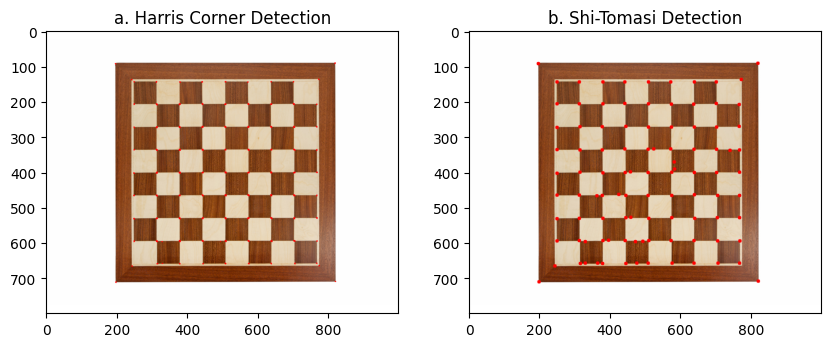

In [7]:
img_harris = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/chess-board.jpg')
gray_harris = cv.cvtColor(img_harris, cv.COLOR_BGR2GRAY)
gray_harris = np.float32(gray_harris)
dst = cv.cornerHarris(gray_harris, 2, 3, 0.04)
dst = cv.dilate(dst, None)
img_harris[dst > 0.01 * dst.max()] = [0, 0, 255]

img_shitomasi = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/chess-board.jpg')
gray_shitomasi = cv.cvtColor(img_shitomasi, cv.COLOR_BGR2GRAY)
corners = cv.goodFeaturesToTrack(gray_shitomasi, 100, 0.01, 10)
corners = np.intp(corners)
for i in corners:
    x, y = i.ravel()
    cv.circle(img_shitomasi, (x, y), 5, (0, 0, 255), -1)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(cv.cvtColor(img_harris, cv.COLOR_BGR2RGB)), plt.title('a. Harris Corner Detection')
plt.subplot(122), plt.imshow(cv.cvtColor(img_shitomasi, cv.COLOR_BGR2RGB)), plt.title('b. Shi-Tomasi Detection')
plt.show()

### 6. Grid Detection (Hough Transform)
Menggunakan `sudoku.jpg`.


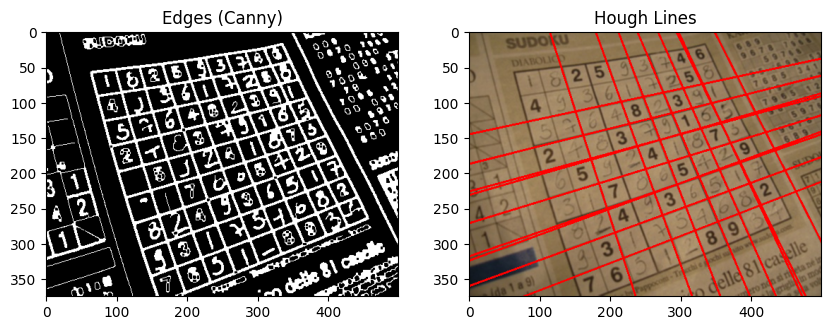

In [14]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

img = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/sudoku.jpg')
# Gunakan copy image agar original tidak tertimpa jika sel dijalankan berulang
img_line = img.copy()

gray = cv.cvtColor(img_line, cv.COLOR_BGR2GRAY)
edges = cv.Canny(gray, 50, 150, apertureSize=3)

kernel = np.ones((3,3), np.uint8)
edges = cv.dilate(edges, kernel, iterations=1)
edges = cv.erode(edges, kernel, iterations=1)

# UBAH NILAI THRESHOLD DI SINI (Sebelumnya 200, coba naikkan ke 300 atau 350)
lines = cv.HoughLines(edges, 1, np.pi/180, 300)

# Tambahkan pengecekan agar tidak error jika tidak ada garis yang terdeteksi
if lines is not None:
    for line in lines:
        rho, theta = line[0]
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * (a))
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * (a))
        cv.line(img_line, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(edges, cmap='gray'), plt.title('Edges (Canny)')
plt.subplot(122), plt.imshow(cv.cvtColor(img_line, cv.COLOR_BGR2RGB)), plt.title('Hough Lines')
plt.show()

### 7. Contour Detection
Menggunakan `laptop.jpg`.


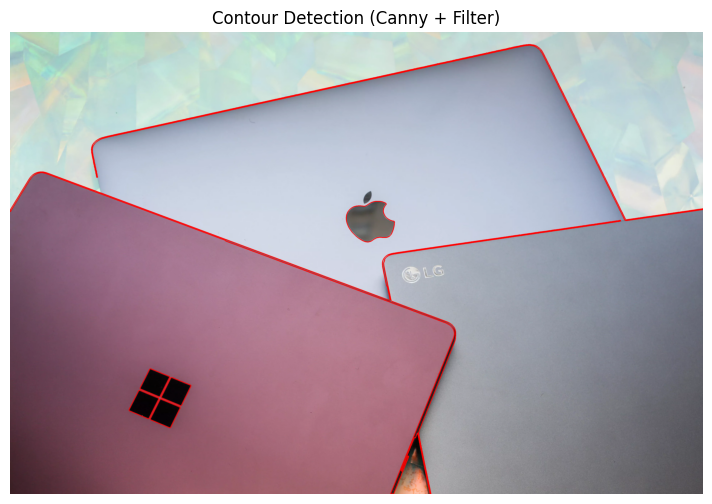

In [16]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Baca gambar
img = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/laptop.jpg')
img_copy = img.copy() # Simpan salinan asli untuk digambar

# 2. Konversi ke Grayscale dan Blur (untuk mengurangi noise)
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
img_blur = cv.GaussianBlur(img_gray, (5, 5), 0)

# 3. Edge Detection menggunakan Canny (bukan threshold biasa)
# Angka 50 dan 150 bisa disesuaikan (semakin kecil semakin sensitif)
edges = cv.Canny(img_blur, 50, 150)

# 4. Morfologi (Dilasi) untuk menyambung garis tepi yang terputus
kernel = np.ones((5,5), np.uint8)
edges = cv.dilate(edges, kernel, iterations=1)

# 5. Cari Kontur
contours, hierarchy = cv.findContours(edges, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

# 6. Filter kontur: Hanya ambil kontur dengan area yang besar (mengabaikan noise kecil)
valid_contours = []
for cnt in contours:
    area = cv.contourArea(cnt)
    if area > 10000: # Sesuaikan angka ini dengan ukuran gambar
        valid_contours.append(cnt)

# 7. Gambar kontur yang sudah difilter (warna merah dalam BGR: (0, 0, 255))
# Karena kita akan menampilkan dengan Matplotlib (RGB), kita gunakan warna Merah di BGR
cv.drawContours(img_copy, valid_contours, -1, (0, 0, 255), 3)

# 8. Tampilkan hasil
plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(img_copy, cv.COLOR_BGR2RGB))
plt.title('Contour Detection (Canny + Filter)')
plt.axis('off') # Opsional: hilangkan sumbu koordinat agar lebih rapi
plt.show()